# Sound Data Collection, Processing and Voiceprint Verification Model

Part 3 of Formative 2 (Group 14). Each member recorded two phrases: "Yes, approve" and "Confirm transaction". All audio processing uses librosa.

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Audio, display
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.audio_features import PHRASES, SR, augment, build_feature_table, find_audio, load_audio
from src import voice_model

AUDIO_DIR = "data/audio"
UNAUTHORIZED_DIR = "data/unauthorized/audio"
sns.set_theme(style="whitegrid")

## 1. Load the recordings

The original recordings came as `.m4a` (phone voice notes) and `.ogg` (WhatsApp). They were converted once with ffmpeg to 16 kHz mono `.wav` and renamed to `yes_approve.wav` and `confirm_transaction.wav`. Loading resamples to 16 kHz and trims leading and trailing silence.

In [2]:
recordings = list(find_audio(AUDIO_DIR))
members = sorted({m for m, _, _ in recordings})
lookup = {(m, p): path for m, p, path in recordings}
clips = {(m, p): load_audio(path) for (m, p), path in lookup.items()}

pd.DataFrame([{"member": m, "phrase": p, "seconds (trimmed)": round(len(y) / SR, 2)}
              for (m, p), y in clips.items()])

,member,phrase,seconds (trimmed)
0,belyse,confirm_transaction,1.90
1,belyse,yes_approve,1.58
2,kyla,confirm_transaction,1.41
3,kyla,yes_approve,1.15
4,rashid,confirm_transaction,1.86
5,rashid,yes_approve,2.82
6,sandrine,confirm_transaction,2.50
7,sandrine,yes_approve,2.34


In [3]:
for (m, p), y in clips.items():
    print(m, "-", p)
    display(Audio(y, rate=SR))

belyse - confirm_transaction


belyse - yes_approve


kyla - confirm_transaction


kyla - yes_approve


rashid - confirm_transaction


rashid - yes_approve


sandrine - confirm_transaction


sandrine - yes_approve


## 2. Waveforms

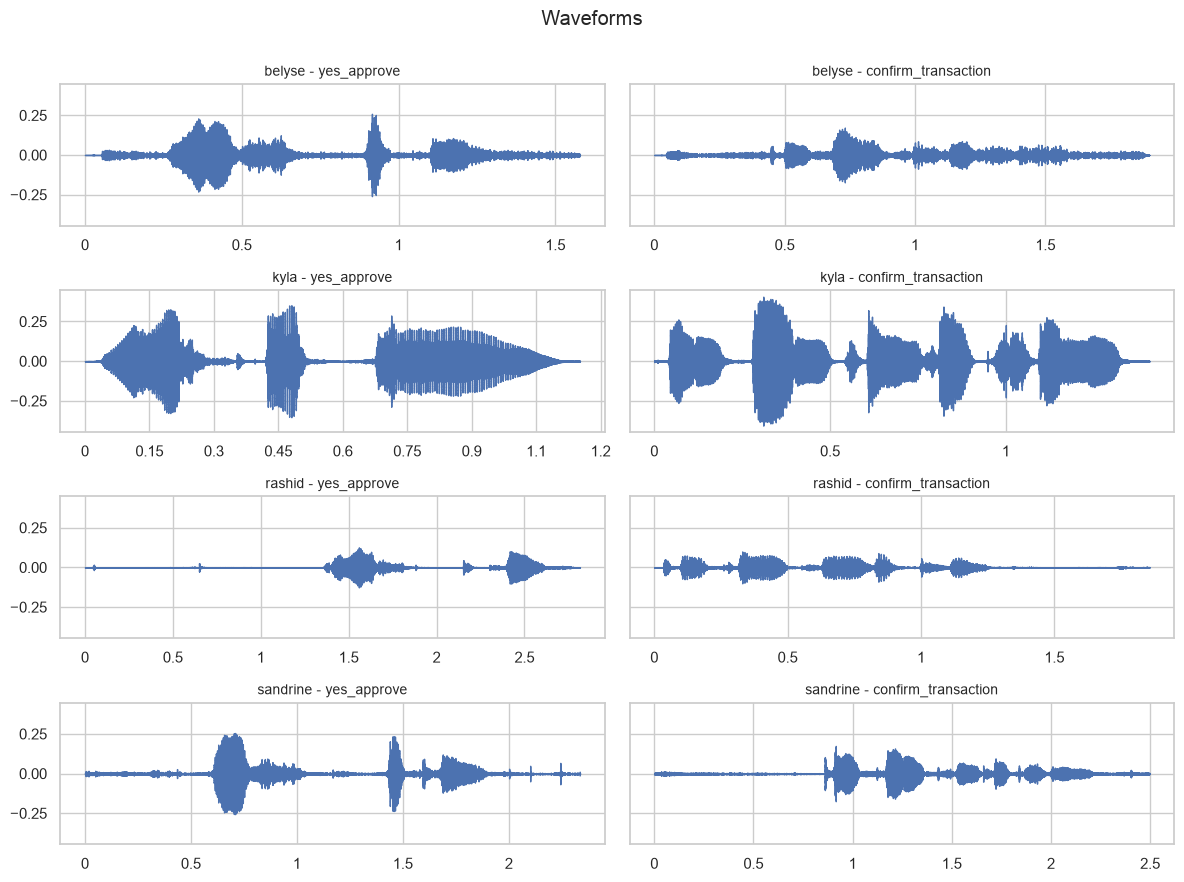

In [4]:
fig, axes = plt.subplots(len(members), len(PHRASES), figsize=(12, 2.2 * len(members)), squeeze=False, sharey=True)
for i, m in enumerate(members):
    for j, p in enumerate(PHRASES):
        ax = axes[i, j]
        if (m, p) in clips:
            librosa.display.waveshow(clips[(m, p)], sr=SR, ax=ax)
        ax.set_title(f"{m} - {p}", fontsize=10)
        ax.set_xlabel("")
plt.suptitle("Waveforms", y=1.0)
plt.tight_layout()
plt.show()

## 3. Spectrograms

Linear-frequency spectrogram (STFT in dB) and mel spectrogram for every recording.

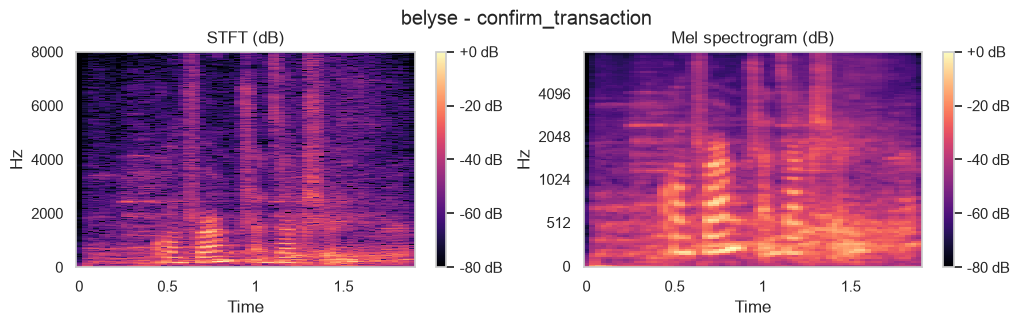

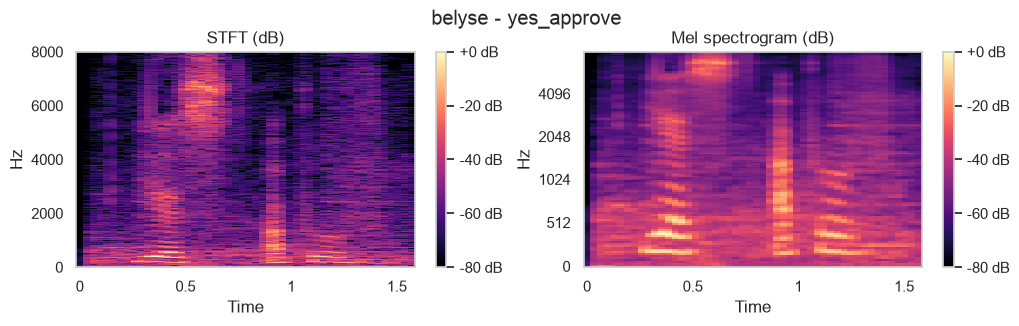

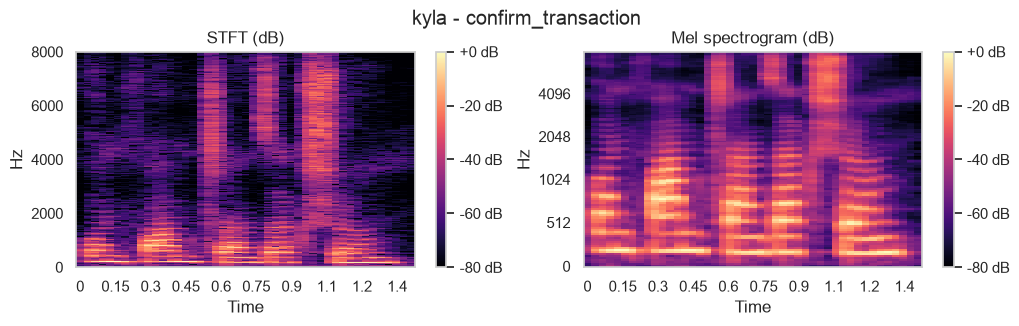

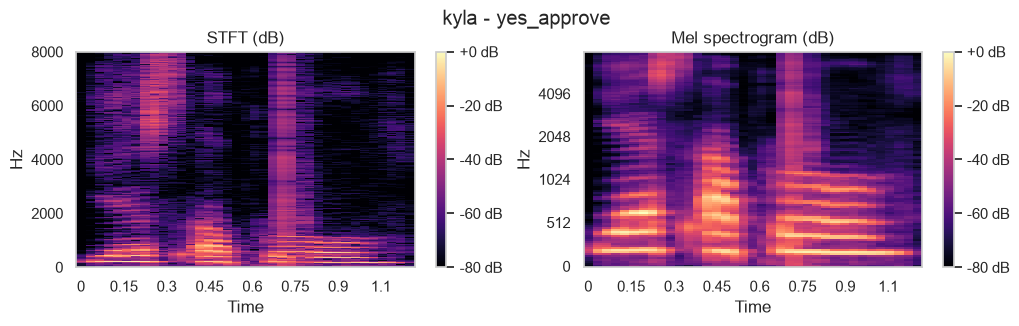

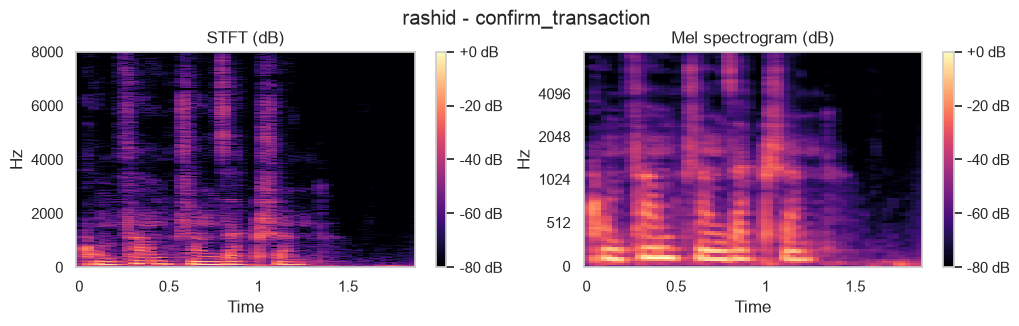

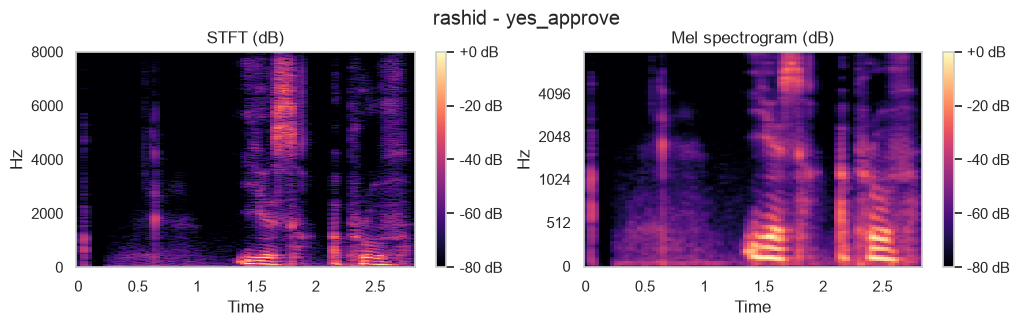

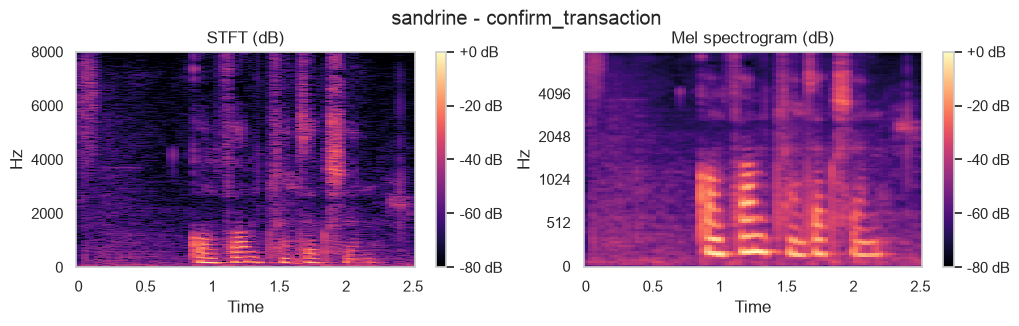

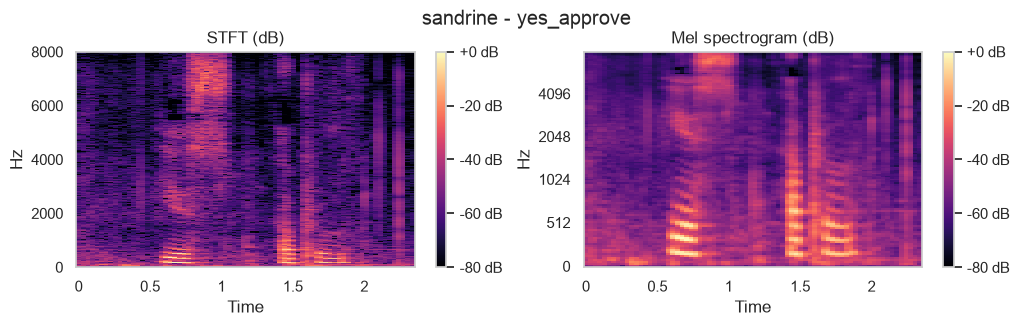

In [5]:
def show_spectrograms(y, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
    stft_db = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(stft_db, sr=SR, x_axis="time", y_axis="hz", ax=axes[0])
    axes[0].set_title("STFT (dB)")
    fig.colorbar(img, ax=axes[0], format="%+2.0f dB")
    mel_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR), ref=np.max)
    img = librosa.display.specshow(mel_db, sr=SR, x_axis="time", y_axis="mel", ax=axes[1])
    axes[1].set_title("Mel spectrogram (dB)")
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
    plt.suptitle(title, y=1.03)
    plt.show()

for (m, p), y in clips.items():
    show_spectrograms(y, f"{m} - {p}")

## 4. Augmentation

Every recording gets 7 augmented versions: pitch shift (+2 and -2 semitones), time stretch (1.1x faster and 0.9x slower), background noise, louder and quieter.

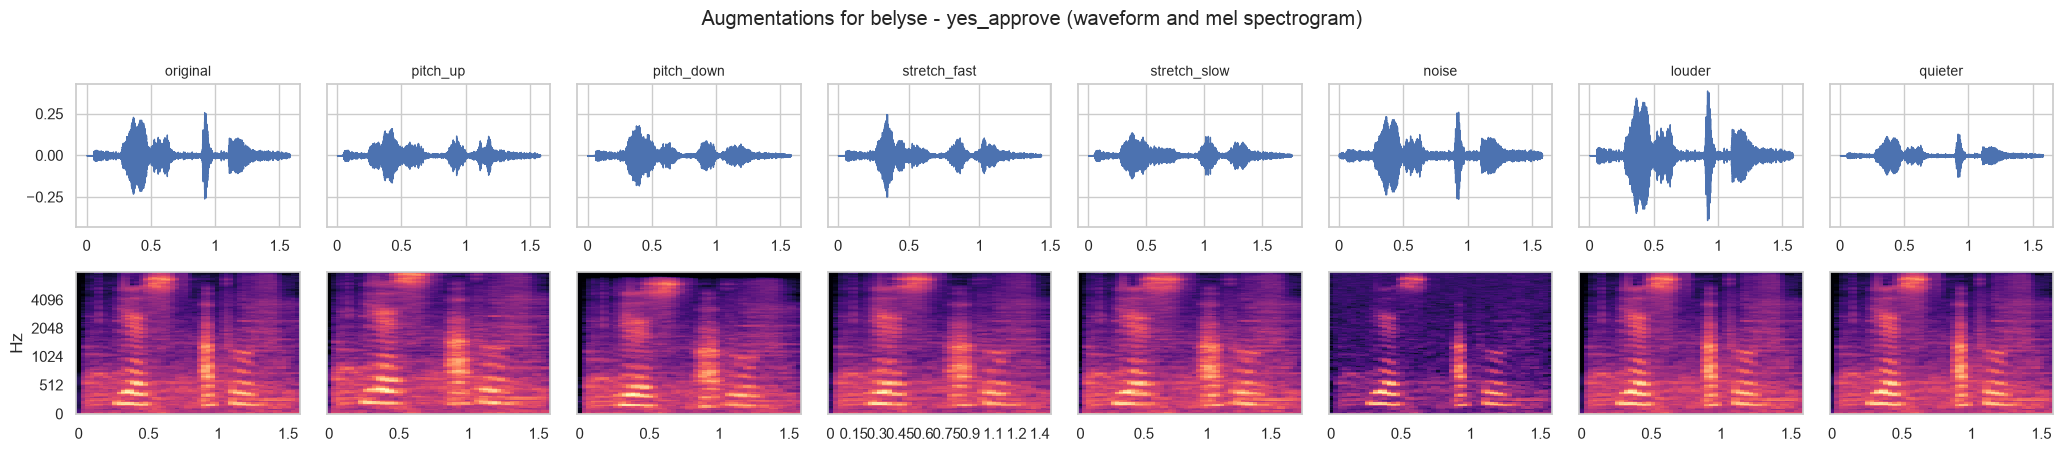

pitch_up


stretch_slow


noise


In [6]:
example = members[0], PHRASES[0]
versions = augment(clips[example])
fig, axes = plt.subplots(2, len(versions), figsize=(2.6 * len(versions), 4.5), sharey="row")
for k, (name, y) in enumerate(versions.items()):
    librosa.display.waveshow(y, sr=SR, ax=axes[0, k])
    axes[0, k].set_title(name, fontsize=10)
    axes[0, k].set_xlabel("")
    mel_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR), ref=np.max)
    librosa.display.specshow(mel_db, sr=SR, x_axis="time", y_axis="mel", ax=axes[1, k])
    axes[1, k].set_xlabel("")
    if k:
        axes[1, k].set_ylabel("")
plt.suptitle(f"Augmentations for {example[0]} - {example[1]} (waveform and mel spectrogram)", y=1.0)
plt.tight_layout()
plt.show()

for name in ["pitch_up", "stretch_slow", "noise"]:
    print(name)
    display(Audio(versions[name], rate=SR))

## 5. Feature extraction

For every version of every recording, the mean and standard deviation over time of:

- 20 MFCCs and their deltas (the shape of the vocal tract, which is what identifies a speaker)
- spectral roll-off, centroid and bandwidth (where the energy sits in the spectrum)
- RMS energy (loudness)
- zero-crossing rate (noisiness)

In [7]:
df = build_feature_table(AUDIO_DIR)
df.to_csv("features/audio_features.csv", index=False)
feature_cols = [c for c in df.columns if c not in voice_model.META_COLS]
print(f"audio_features.csv: {df.shape[0]} rows, {len(feature_cols)} features")
df[voice_model.META_COLS + feature_cols[:4] + ["rolloff_mean", "rms_mean"]].head()

audio_features.csv: 64 rows, 90 features


,member,phrase,source_file,augmentation,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,rolloff_mean,rms_mean
0,belyse,confirm_transaction,data/audio/belyse/confirm_transaction.wav,original,-308.920779,73.582595,105.620258,32.056036,3137.630208,0.018330
1,belyse,confirm_transaction,data/audio/belyse/confirm_transaction.wav,pitch_up,-334.206949,64.031445,102.738384,27.064668,3189.062500,0.013010
2,belyse,confirm_transaction,data/audio/belyse/confirm_transaction.wav,pitch_down,-351.769178,68.326931,120.399338,27.427410,2763.932292,0.013132
3,belyse,confirm_transaction,data/audio/belyse/confirm_transaction.wav,stretch_fast,-333.038879,67.517333,103.285385,26.692288,3286.024306,0.012080
4,belyse,confirm_transaction,data/audio/belyse/confirm_transaction.wav,stretch_slow,-336.254761,66.864679,104.220066,29.098271,3209.280303,0.012925


In [8]:
df.groupby(["member", "augmentation"]).size().unstack()

augmentation,louder,noise,original,pitch_down,pitch_up,quieter,stretch_fast,stretch_slow
member,,,,,,,,
belyse,2,2,2,2,2,2,2,2
kyla,2,2,2,2,2,2,2,2
rashid,2,2,2,2,2,2,2,2
sandrine,2,2,2,2,2,2,2,2


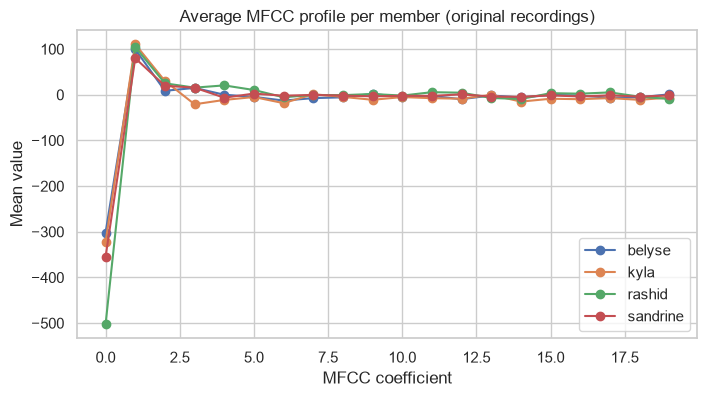

In [9]:
mfcc_cols = [f"mfcc_{i}_mean" for i in range(20)]
originals = df[df["augmentation"] == "original"]
fig, ax = plt.subplots(figsize=(8, 4))
for m in members:
    ax.plot(originals.loc[originals["member"] == m, mfcc_cols].mean().values, marker="o", label=m)
ax.set_xlabel("MFCC coefficient")
ax.set_ylabel("Mean value")
ax.set_title("Average MFCC profile per member (original recordings)")
ax.legend()
plt.show()

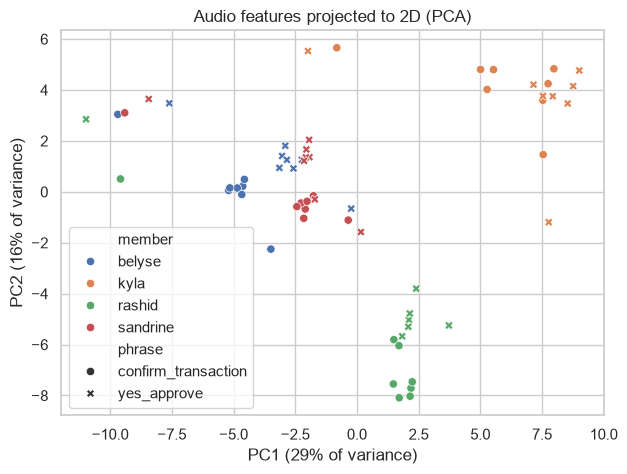

In [10]:
pca = PCA(n_components=2)
coords = pca.fit_transform((df[feature_cols] - df[feature_cols].mean()) / (df[feature_cols].std() + 1e-8))
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["member"], style=df["phrase"], ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Audio features projected to 2D (PCA)")
plt.show()

## 6. Voiceprint verification model

Evaluation is leave-one-phrase-out: the model is trained on one phrase (with its augmentations) and tested on the other phrase, which it has never heard in any form. This is repeated for both phrases, so the model has to recognise the speaker and not the words.

The same three models as the face model are compared on accuracy, macro F1 and log loss.

In [11]:
results, confidences = voice_model.evaluate(df)
results.round(3)

,model,held_out,accuracy,f1,log_loss
0,logistic_regression,confirm_transaction,0.812,0.802,0.504
1,logistic_regression,yes_approve,0.625,0.605,0.750
2,random_forest,confirm_transaction,0.969,0.969,0.853
3,random_forest,yes_approve,0.688,0.621,0.928
4,xgboost,confirm_transaction,0.500,0.489,0.768
5,xgboost,yes_approve,0.844,0.849,0.524


In [12]:
summary = results.groupby("model")[["accuracy", "f1", "log_loss"]].mean().round(3)
summary

,accuracy,f1,log_loss
model,,,
logistic_regression,0.719,0.703,0.627
random_forest,0.828,0.795,0.890
xgboost,0.672,0.669,0.646


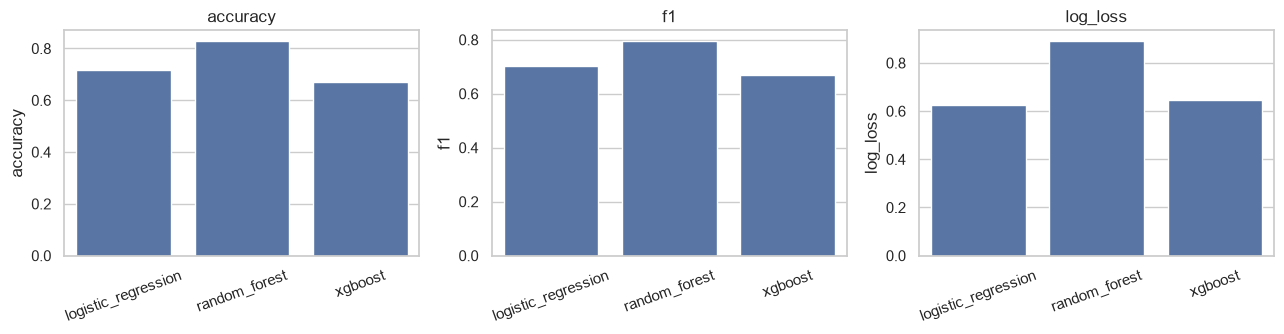

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ["accuracy", "f1", "log_loss"]):
    sns.barplot(data=results, x="model", y=metric, ax=ax, errorbar=None)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Best model: random_forest


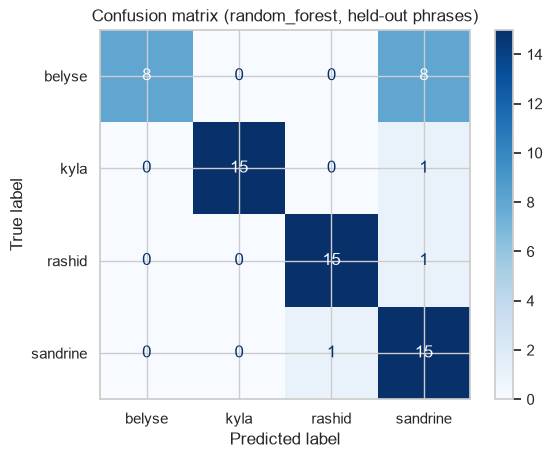

In [14]:
best = summary["f1"].idxmax()
print("Best model:", best)
y_true, y_pred = voice_model.held_out_predictions(df, best)
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=members), display_labels=members).plot(cmap="Blues")
plt.title(f"Confusion matrix ({best}, held-out phrases)")
plt.show()

## 7. Final model and rejecting unknown voices

A classifier always picks one of the known members, so a voice is only accepted when:

1. the model's confidence is above a threshold
2. the voice is close enough (cosine distance) to that member's own recordings

In the full system the accepted voice must also belong to the same member the face model recognised (`voice_model.verify`).

In [15]:
distances = voice_model.genuine_distances(df)
bundle = voice_model.train_final(df, best, confidences, distances)
voice_model.save(bundle, "models/voice_model.pkl")
print(f"Saved models/voice_model.pkl ({best})")
print(f"Confidence threshold: {bundle['threshold']:.3f}")
print(f"Distance threshold:   {bundle['distance_threshold']:.3f}")

Saved models/voice_model.pkl (random_forest)
Confidence threshold: 0.400
Distance threshold:   0.652


## 8. Test: known members and an unauthorized voice

The unauthorized sample is a non-member saying the same phrase, placed in `data/unauthorized/audio/`.

In [16]:
tests = [(m, lookup[(m, p)]) for m in members for p in PHRASES if (m, p) in lookup]
unauthorized = [os.path.join(UNAUTHORIZED_DIR, f) for f in sorted(os.listdir(UNAUTHORIZED_DIR))
                if f.lower().endswith(".wav")]
tests += [("unauthorized", path) for path in unauthorized]

rows = []
for who, path in tests:
    member, conf, dist = voice_model.predict_voice(path, bundle)
    rows.append({"voice of": who, "file": os.path.basename(path), "predicted": member or "ACCESS DENIED",
                 "confidence": round(conf, 3), "distance": round(dist, 3)})
checks = pd.DataFrame(rows)
checks

,voice of,file,predicted,confidence,distance
0,belyse,yes_approve.wav,belyse,0.990,0.0
1,belyse,confirm_transaction.wav,belyse,0.973,0.0
2,kyla,yes_approve.wav,kyla,0.993,0.0
3,kyla,confirm_transaction.wav,kyla,1.000,0.0
4,rashid,yes_approve.wav,rashid,0.997,0.0
5,rashid,confirm_transaction.wav,rashid,0.993,0.0
6,sandrine,yes_approve.wav,sandrine,0.997,0.0
7,sandrine,confirm_transaction.wav,sandrine,0.993,0.0


In [17]:
# Self-check: members are verified as themselves, nobody else gets through.
for m in members:
    for p in PHRASES:
        if (m, p) in lookup:
            assert voice_model.verify(lookup[(m, p)], m, bundle), f"{m} - {p} was not verified"
for path in unauthorized:
    assert voice_model.predict_voice(path, bundle)[0] is None, f"unauthorized voice accepted: {path}"
if not unauthorized:
    print(f"No unauthorized sample in {UNAUTHORIZED_DIR} yet")
print("All checks passed")

No unauthorized sample in data/unauthorized/audio yet
All checks passed


## Summary

Each member recorded "Yes, approve" and "Confirm transaction". The recordings came in as `.m4a` and `.ogg`, so they were converted once with ffmpeg to 16 kHz mono `.wav` files with the same names for every member.

With librosa, every recording is trimmed of silence, displayed as a waveform and spectrogram, and augmented 7 ways (pitch shift up and down, time stretch faster and slower, background noise, louder, quieter). MFCCs and their deltas, spectral roll-off, centroid and bandwidth, RMS energy and zero-crossing rate are summarised by their mean and standard deviation and saved to `features/audio_features.csv`.

The voiceprint model is evaluated leave-one-phrase-out, so it is always tested on a phrase it never heard from that speaker. The best model by F1 is saved to `models/voice_model.pkl` together with a confidence threshold and a distance threshold, which are meant to reject voices that do not belong to any member.

The main limitation is the amount of data. With two recordings per member, each fold trains on a single real recording per member, so the scores are noisy and the thresholds are loose: a member's own unseen phrase sits about as far from their training recording as a stranger's voice does. Each member also recorded on a different phone and app, so part of what the model learns is the recording channel rather than the voice. More recordings per member, ideally on the same device, are the main way to make the rejection reliable.